In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,...,Eigenvectors_higher_precision1,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2
0,(2.2580592012418523-8.201465449229e-12j),(-0.00015663500465572217+5.5771468589364595e-05j),0.00000,-1.99875,(4.892729115054892e-07+4.83811925086966e-07j),(3.5713356402153393-8.086188447618218e-10j),(3.1033459296932165e-05+0.0005637376884440758j),0.00000,-1.99875,(1.1982488096997846e-05-7.423943442461415e-07j),...,(0.0013131517818197453-0.0003498609994314424j),-0.157304,-1.992522,(1.185773705789858e-05-6.91885643175588e-07j),-1.179783,-0.265305,1.022238,0.253194,1.931348,0.514196
1,NaN,(-0.00015341876417562992+6.075480363353627e-05j),-0.41000,-1.94750,(3.026544656219046e-06+2.99906337227889e-06j),NaN,(4.1186800513665875e-05+0.0004289098509225647j),-0.41000,-1.94750,(7.899035648071249e-05-4.829985836120071e-06j),...,(0.001437084492083064-0.0003803787218140587j),-0.148565,-1.992522,(1.800377073307381e-05-1.1953754710583835e-06j),-1.188522,-0.268639,1.021902,0.253435,1.922609,0.515175
2,NaN,(-0.00014634494486743589+7.168256656191743e-05j),-0.35875,-1.94750,(6.407683487669424e-06+6.3373395713712155e-06j),NaN,(5.107729420095911e-05+0.00030654615441474736j),-0.35875,-1.94750,(0.000164798521004597-1.026790626842153e-05j),...,(0.001587822847480625-0.00043172560285411905j),-0.139826,-1.992522,(2.3821228702243112e-05-1.692348580034273e-06j),-1.195836,-0.270913,1.013739,0.257371,1.913870,0.513219
3,NaN,(-0.0001406253073599407+8.048659513901056e-05j),-0.30750,-1.94750,(9.664182330412061e-06+9.550553861938045e-06j),NaN,(5.5198191256352114e-05+0.00023993216825224665j),-0.30750,-1.94750,(0.0002449012993782059-1.5395977725020274e-05j),...,(0.0016860399465770655-0.00047133363533671883j),-0.131087,-1.992522,(2.9347350439259834e-05-2.1338793057925406e-06j),-1.197261,-0.271147,1.005000,0.259242,1.905130,0.510886
4,NaN,(-0.00012853805691023286+9.900047632857338e-05j),-0.25625,-1.94750,(1.2724873052343624e-05+1.2581744265313584e-05j),NaN,(5.73955074168369e-05+0.0001316708803754342j),-0.25625,-1.94750,(0.00031764965318147335-1.9814296181261697e-05j),...,(0.001867393521545228-0.0005547265570844337j),-0.122348,-1.992522,(3.485092969398505e-05-2.2100386134533577e-06j),-1.206000,-0.273407,0.996261,0.260890,1.896391,0.508416
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.122348,1.992522,(-3.485092819640439e-05+2.2100413666637777e-06j),NaN,NaN,NaN,NaN,NaN,NaN
154571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.131087,1.992522,(-2.9347348963988865e-05+2.1338820133374493e-06j),NaN,NaN,NaN,NaN,NaN,NaN
154572,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.139826,1.992522,(-2.3821227250544623e-05+1.6923512400595763e-06j),NaN,NaN,NaN,NaN,NaN,NaN
154573,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.148565,1.992522,(-1.8003769305690695e-05+1.19537808162195e-06j),NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([55,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

a_big_ell = 2
b_big_ell = 2
xm_big_ell = 0
ym_big_ell = 0
rot_big_ell = 0
n_ellipses = 6

# Parameters for the inner ellpses
a_small_ell = 0.1
b_small_ell = 0.4
distance_small_ell = 1.1
angles_small_ell = np.linspace(0,2*np.pi, n_ellipses, endpoint=False)
xm_small_ell = distance_small_ell*np.cos(angles_small_ell)
ym_small_ell = distance_small_ell*np.sin(angles_small_ell)
rot_small_ell = angles_small_ell

# Parameters for the inner hypotrochoid
xa_hyp = 0.6
xi_hyp = 0.5
A_hyp = n_ellipses
r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
R_hyp = A_hyp*r_hyp
a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
xm_hyp = 0
ym_hyp = 0
rot_hyp = 0

vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,0,0,0,a_small_ell,b_small_ell,distance_small_ell,n_ellipses,n[0],alpha)


In [7]:
hypotrochoid = DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,xm_hyp,ym_hyp,rot_hyp,n[0])

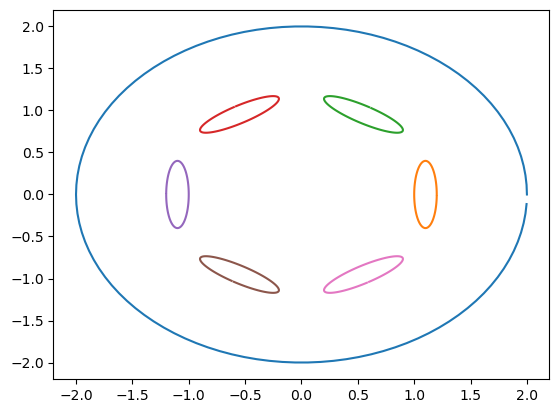

In [8]:
for i in range(n_ellipses+1):
    plt.plot(vi[i][0,:], vi[i][1,:])

In [9]:
#for i in range(vi_first_eig.shape[0]):
vi_closed_curve = np.dstack((vi,vi[:,:,0:1]))

In [10]:
hypotrochoid_closed_curve =  np.hstack((hypotrochoid,hypotrochoid[:,-2:-1]))

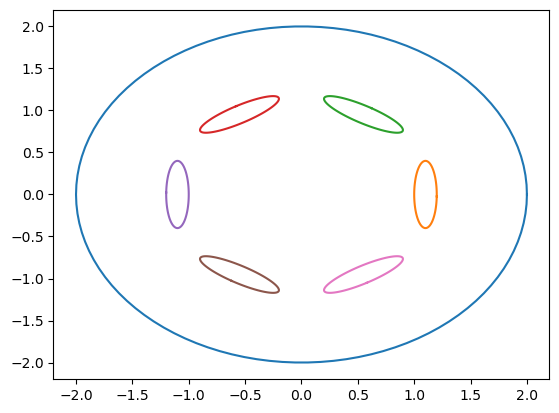

In [11]:
for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:])

In [12]:
def ray_tracing_in_holes(boundary, xmid, ymid, radius):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    xmid : numpy.ndarray
        x-Positions of all points that should be checked to be inside the given domain without holes.
    ymid : numpy.ndarray
        y-Positions of all points that should be checked to be inside the given domain without holes.
    radius : float
        Adds or subtracts a margin around a path to make the enclosed area slightly larger or smaller.

    Returns
    -------
    inside_any : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh,radius=radius) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [13]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(2.2580592012418523-8.201465449229e-12j)'

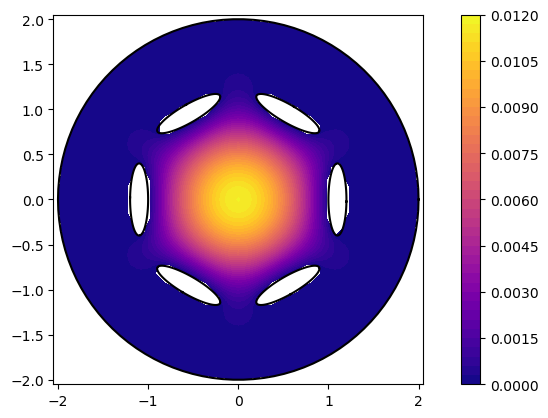

In [14]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, radius=0.0)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, radius=0.0)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, radius=0.0)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, radius=0.0)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, radius=0.0)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, radius=0.0)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, radius=0.0)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)
# Kontur-Plot
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40)
plt.colorbar()
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)

for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i,0,:], vi_closed_curve[i,1,:], 'black')

plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)
plt.show()

In [15]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

'(3.5713356402153393-8.086188447618218e-10j)'

In [16]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [17]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [18]:
big_ellipse = DL.create_ellipse(a_big_ell,b_big_ell,xm_big_ell,ym_big_ell,rot_big_ell,n[0])
small_ellipses = np.array([np.flip(DL.create_ellipse(a_small_ell,b_small_ell,xm_small_ell[i],ym_small_ell[i],rot_small_ell[i],n[0]),1) for i in range(n_ellipses)])

In [19]:
radius = 0.01

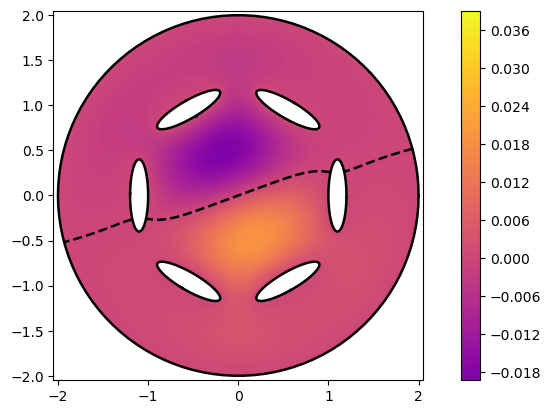

In [20]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

big_ellipse_append = np.concatenate((big_ellipse, big_ellipse[:,0].reshape(2,1)), axis=1)
small_ellipses_append = np.concatenate((small_ellipses, small_ellipses[:,:,0].reshape(small_ellipses.shape[0],2,1)), axis=2)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]
# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.01)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.01)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.01)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.01)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.01)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.01)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.01)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)

# Kontur-Plot
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 250, vmin=vmin_sol, vmax=vmax_sol)
plt.colorbar()
cf1 = plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.plot(big_ellipse_append[0,:], big_ellipse_append[1,:], 'black', linewidth = 1.8)
for i in range(small_ellipses_append.shape[0]):
    plt.plot(small_ellipses_append[i][0,:], small_ellipses_append[i][1,:], 'black', linewidth = 1.8)

plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.show()

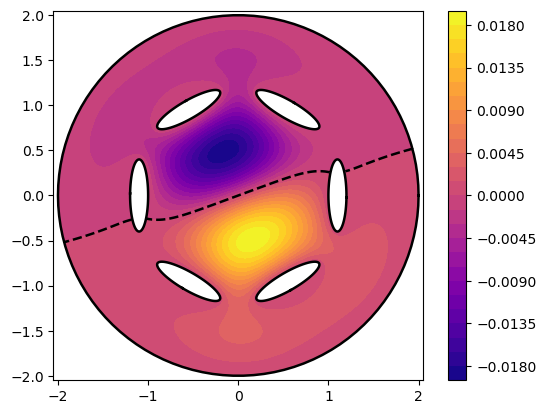

In [21]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

big_ellipse_append = np.concatenate((big_ellipse, big_ellipse[:,0].reshape(2,1)), axis=1)
small_ellipses_append = np.concatenate((small_ellipses, small_ellipses[:,:,0].reshape(small_ellipses.shape[0],2,1)), axis=2)

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
x_boundary = x_inside[triang.triangles]
y_boundary = y_inside[triang.triangles]
x_boundary_flatten = x_boundary.flatten()
y_boundary_flatten = y_boundary.flatten()
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)

mask1_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), x_boundary_flatten, y_boundary_flatten, 0.01)
mask2_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask3_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask4_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask5_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask6_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask7_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), x_boundary_flatten, y_boundary_flatten, -0.01)

mask1_reshape = mask1_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask2_reshape = mask2_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask3_reshape = mask3_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask4_reshape = mask4_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask5_reshape = mask5_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask6_reshape = mask6_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask7_reshape = mask7_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask1_boundary = mask1_reshape.any(axis=0)
mask2_boundary = mask2_reshape.any(axis=0)
mask3_boundary = mask3_reshape.any(axis=0)
mask4_boundary = mask4_reshape.any(axis=0)
mask5_boundary = mask5_reshape.any(axis=0)
mask6_boundary = mask6_reshape.any(axis=0)
mask7_boundary = mask7_reshape.any(axis=0)

mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.01)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.01)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.01)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.01)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.01)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.01)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.01)

mask1_inv = ~mask1
mask1_inv_boundary = ~mask1_boundary
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask1_inv_boundary |  mask2_boundary | mask3_boundary | mask4_boundary | mask5_boundary | mask6_boundary | mask7_boundary

triang.set_mask(mask)

# Kontur-Plot
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 30)
cf1 = plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.plot(big_ellipse_append[0,:], big_ellipse_append[1,:], 'black', linewidth = 1.8)
for i in range(small_ellipses_append.shape[0]):
    plt.plot(small_ellipses_append[i][0,:], small_ellipses_append[i][1,:], 'black', linewidth = 1.8)

plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.colorbar(cf, label='')
plt.savefig('circle_five_ellipses_end_result.eps', format="eps")
plt.show()